In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## roc-curve

**Figure 1: ROC curves of three toxicity classifiers on the test set.** Legend entries give the area under each curve (AUC). Our classifier lies above both baselines at every operating point, with an AUC of 0.940 against 0.900 for fine-tuned BERT and 0.830 for logistic regression.

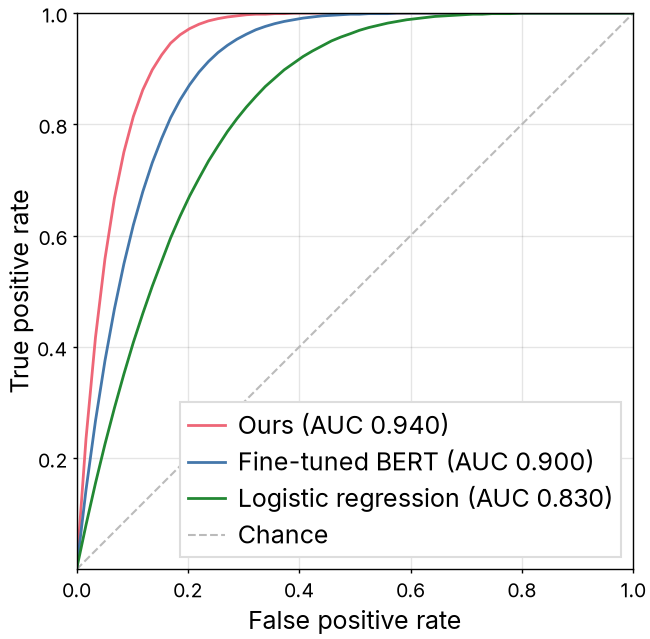

In [2]:
with open("../roc-curve.json") as f:
    roc = json.load(f)

methods = {
    "Ours": colors["ours"],
    "Fine-tuned BERT": colors["series-1"],
    "Logistic regression": colors["series-3"],
}

fig, ax = plt.subplots(figsize=(3.25, 3.25))
for name, color in methods.items():
    fpr, tpr = roc[name]["fpr"], roc[name]["tpr"]
    auc = np.trapezoid(tpr, fpr)
    ax.plot(fpr, tpr, color=color, label=f"{name} (AUC {auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=0.75, color=colors["neutral"], zorder=1, label="Chance")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend(loc="lower right")

fit_height(fig, ax, aspect=1.0)
fig.savefig("roc-curve.pdf")
fig.savefig("roc-curve.png")
plt.show()

## scaling-curve

**Figure 2: Validation loss against model size for dense and mixture-of-experts (MoE) models.** The x axis is log scale; dashed lines mark each family's loss at the largest size. Our MoE models reach a lower loss than dense models at every size, from 0.155 lower at 70M parameters to 0.087 lower at 12B (2.288 vs. 2.375).

figures/paper.py:228: UserWarning: 2.375 covers a curve in panel ''; move it
  warnings.warn(f"{name} covers a curve in panel {a.get_title()!r}; move it")


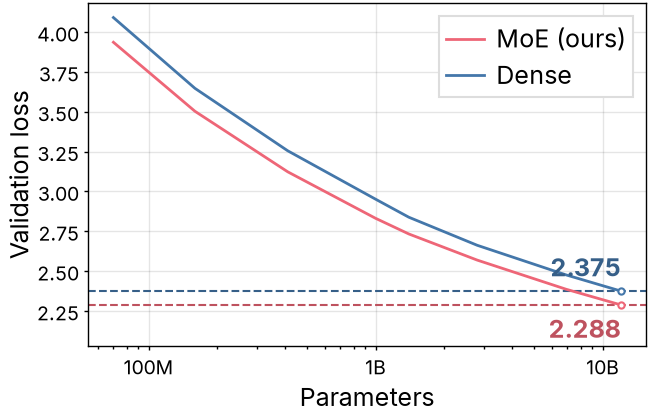

In [3]:
with open("../scaling-curve.json") as f:
    scaling = json.load(f)
params = scaling["params"]

families = {
    "MoE (ours)": colors["ours"],
    "Dense": colors["series-1"],
}

fig, ax = plt.subplots(figsize=(3.25, 2))
for name, color in families.items():
    ax.plot(params, scaling[name], color=color, label=name)
mark_value(ax, params[-1], scaling["Dense"][-1], f"{scaling['Dense'][-1]:.3f}", colors["series-1"])
mark_value(ax, params[-1], scaling["MoE (ours)"][-1], f"{scaling['MoE (ours)'][-1]:.3f}", colors["ours"], below=True)
ax.set_xscale("log")
ax.set_xticks([1e8, 1e9, 1e10], labels=["100M", "1B", "10B"])
ax.tick_params(axis="x", which="minor", labelbottom=False)
ax.set_xlabel("Parameters")
ax.set_ylabel("Validation loss")
ax.legend(loc="upper right")

fit_height(fig, ax, aspect=0.618)
fig.savefig("scaling-curve.pdf")
fig.savefig("scaling-curve.png")
plt.show()